In [11]:
import urllib.request
url = "https://psl.noaa.gov/thredds/fileServer/Datasets/ncep.reanalysis2.derived/surface/mslp.mon.mean.nc"
urllib.request.urlretrieve(url, "mslp.mon.mean.nc")

('mslp.mon.mean.nc', <http.client.HTTPMessage at 0x7a3011bae2d0>)

## 오늘 할 일

- **Practice 1**: 전주에 12월 비가 많은 해, 12월 해면기압(SLP)은 어떤 모양이었을까?
- **Practice 2**: ENSO의 영향을 빼고 보면, 그 모양은 어떻게 달라질까?

**부분회귀 (partial regression)**

전주 강수와 SLP가 함께 변하더라도, 둘 다 ENSO의 영향을 받은 결과일 수 있다.
그래서 **두 변수 모두에서** ENSO로 설명되는 부분을 빼고, 남은 부분끼리 회귀한다.
$$
y = a x_1 + b x_2 + \varepsilon
$$

$$
(y - a_{x_1,y}\, x_1) = b\,(x_2 - a_{x_1,x_2}\, x_1) + \varepsilon
$$

- $y$ : SLP, $x_2$ : 전주 강수, $x_1$ : ENSO
- $a_{x_1,y}$ : ENSO에 대한 SLP의 회귀계수, $a_{x_1,x_2}$ : ENSO에 대한 강수의 회귀계수
- $b$ : 부분회귀계수 — ENSO의 영향을 뺀 뒤, 강수가 1 mm 증가할 때 SLP의 평균적인 변화량

## Practice 1 Regressed SLP pattern onto Precip_Jeonju

In [1]:
import numpy as np
import pandas as pd
import xarray as xr

import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from scipy.stats import linregress

### 1. Make winter (DEC) Jeonju Precipitation data

자료: https://data.kma.go.kr/data/grnd/selectAsosRltmList.do?pgmNo=36

In [2]:
################ Jeonju Precipitation index ################
data = pd.read_csv('../data/rn_20260928132312.csv', encoding='euc-kr', sep=',', header=6)

datadec = data[pd.to_datetime(data['년월']).dt.month == 12]    # Select December data only

precip = datadec['강수량(mm)']                 # precipitation
dates = pd.DatetimeIndex(datadec['년월'])      # dates

pd1 = pd.DataFrame({'time': dates, '강수량(mm)': precip})    # Make pd frame
pd2 = pd1.set_index(['time'])    # Set 'time' dimension to index
xarr1 = pd2.to_xarray()          # Pandas to xarray dataset
xarr2 = xarr1.to_array()         # xarray dataset to xarray array

# Select time period and make anomaly
pr = xarr2[0,:].sel(time=slice('1982-12','2022-12')) - xarr2[0,:].mean().values
print(pr.shape)                  # (41,)

(41,)


### 2. Make winter (DEC) SLP mapped data

In [3]:
################  Map data (Sea level pressure for Regression) ##################
# ----------- read netcdf file  ------------
dset = xr.open_dataset('../data/mslp.mon.mean.nc')
mslp = dset['mslp']              # 단위: Pa
print(mslp.shape)                # (time, lat, lon)

#---------- Calculate climatology ----------
clim = mslp.sel(time=slice('1982-12','2022-12')).groupby('time.month').mean(dim='time')

#---- Calculate anomalies and select DEC data ---
anomt = (mslp.groupby('time.month') - clim)
anom = anomt.sel(time=slice('1982-12','2022-12'))[0::12]  # DEC
print(anom.shape)                # (41, lat, lon)

# 강수와 SLP의 연도가 같은지 확인 (다르면 여기서 에러가 난다)
assert (pr['time.year'].values == anom['time.year'].values).all()

(561, 73, 144)
(41, 73, 144)


### 3. Conduct regression analysis

In [4]:
#############################  Regression #########################
reg, interc, corr, pval = np.apply_along_axis(lambda y,x: linregress(x,y)[0:4], axis=0, arr=anom.values, x=pr.values)

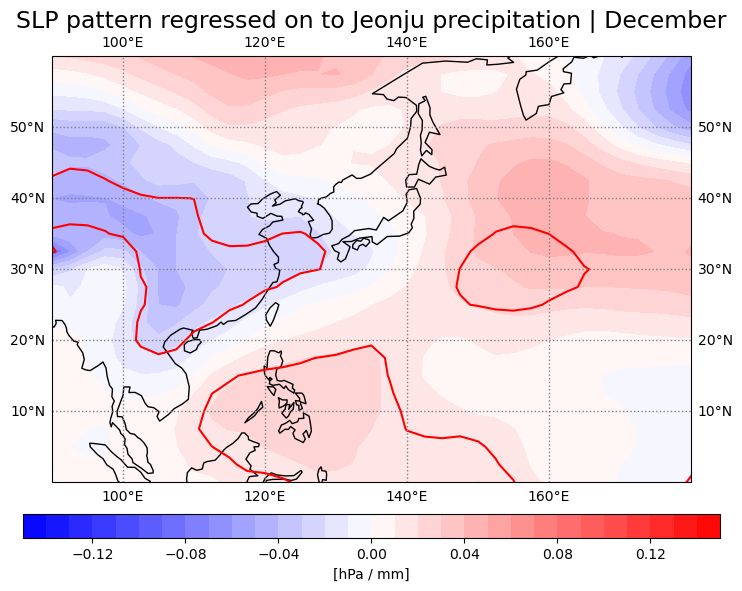

In [5]:
##########################  Plotting  ############################
# ----------- Set Figure  ------------
fig = plt.figure(figsize=(9,7))   # Figure
ax = plt.axes(projection = ccrs.PlateCarree(180))   # Axes
ax.set_extent([90, 180, 0, 60], crs=ccrs.PlateCarree())

# ----------- Plot figure ------------
lons = anom["lon"]
lats = anom["lat"]

clevs = np.arange(-0.15, 0.151, 0.01)
plt.contourf(lons, lats, reg/100, levels = clevs, cmap='bwr', transform=ccrs.PlateCarree())   # /100 : Pa -> hPa
plt.colorbar(orientation = "horizontal", pad=0.06, aspect= 30, label='[hPa / mm]')

plt.contour(lons, lats, pval, levels=[0.10], colors=['red'], transform=ccrs.PlateCarree())

# ----------- Set Axes properties  ------------
ax.set_title('SLP pattern regressed on to Jeonju precipitation | December', fontsize=17)
ax.coastlines()
ax.gridlines(draw_labels=True, linewidth=1, linestyle=':', color='gray')

plt.savefig('jeonju_precip_regression_slp_dec.png')
plt.show()

## Practice 2 Regressed SLP pattern onto Precip_Jeonju after excluding ENSO signal

### 1. Make winter (DEC) Jeonju Precipitation data

Practice 1에서 만든 `pr`을 그대로 쓴다.

### 2. Make winter ENSO index

In [6]:
############################# ENSO index #############################
dset = xr.open_dataset('../data/sst.mnmean.nc')
sst = dset['sst']

#------------ Calculate Nino index ---------
nino34 = sst.where((sst.lat<5) & (sst.lat>-5) & (sst.lon>190) & (sst.lon<240), drop=True).mean(dim=['lat','lon'])

#---------- Calculate climatology ----------
clim = nino34.sel(time=slice('1982-01','2022-12')).groupby('time.month').mean(dim='time')

#---------- Calculate anomalies ------------
nanom = (nino34.groupby('time.month') - clim)

#--------Pick up a specific season ---------
ninos = nanom[12::12]  # DEC
ninos = ninos.sel(time=slice('1982-12','2022-12'))  # pr, anom과 같은 기간으로 맞춘다
print(ninos.shape)               # (41,)

# 강수와 ENSO의 연도가 같은지 확인
assert (pr['time.year'].values == ninos['time.year'].values).all()

(41,)


### 3. Make winter SLP mapped data

Practice 1에서 만든 `anom`을 그대로 쓴다.

### 4. Conduct partial regression analysis

In [7]:
#################################  Exclude ENSO signal #################################
#--- Exclude ENSO signal from Jeonju precip data ----
regnp = linregress(ninos, pr)[0]
prn = pr - regnp*ninos

In [8]:
#----- Exclude ENSO signal from SLP data -----
# .values : xarray 대신 numpy 배열로 넘겨야 regns[None,:,:] 에서 에러가 나지 않는다
regns = np.apply_along_axis(lambda y,x: linregress(x,y)[0], axis=0, arr=anom.values, x=ninos.values)
print(regns.shape)               # (lat, lon)

dummy = regns[None,:,:]          # 맨 앞에 차원을 추가
print(dummy.shape)               # (1, lat, lon)

# 격자마다 (회귀계수 x ninos) 계산 -> 시간 차원이 41개로 늘어난다
regnsninos = np.apply_along_axis(lambda y,x: x*y, axis=0, arr=dummy, x=ninos.values)
print(regnsninos.shape)          # (41, lat, lon)

anomn = anom - regnsninos

(73, 144)
(1, 73, 144)
(41, 73, 144)


In [9]:
########################  Regression ##########################
# reg, interc, corr, pval 은 Practice 1에서 계산했다
partreg, pinterc, pcorr, ppval = np.apply_along_axis(lambda y,x: linregress(x,y)[0:4], axis=0, arr=anomn.values, x=prn.values)

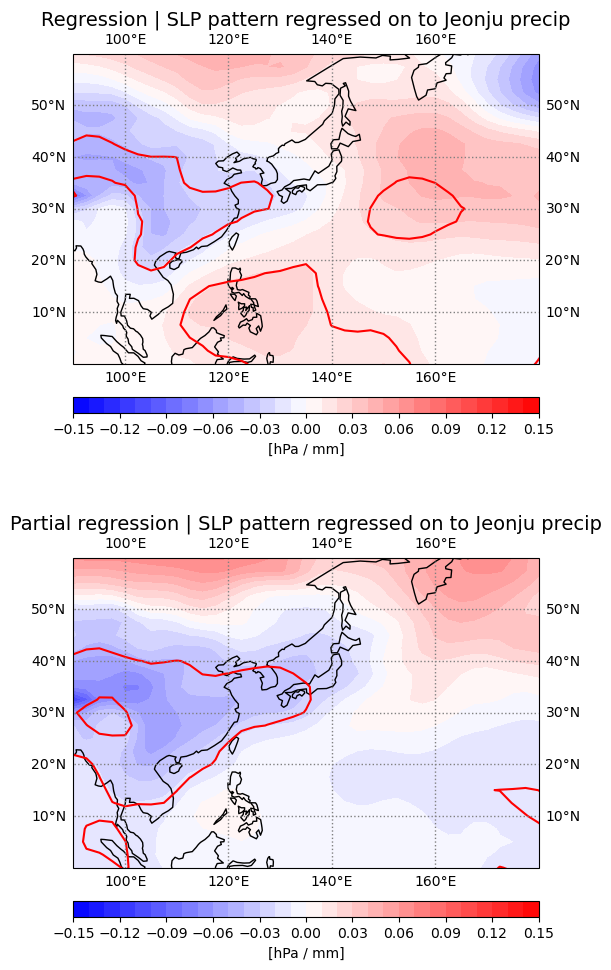

In [10]:
##########################  Plotting  ############################
# ----------- Set Figure  ------------
fig = plt.figure(figsize=(6,12))   # Figure

lons = anom["lon"]
lats = anom["lat"]

clevs = np.around(np.arange(-0.15, 0.151, 0.01), 3)
ticks = np.around(np.arange(-0.15, 0.151, 0.03), 3)

# Sub-Figure 1
ax1 = plt.subplot(211, projection = ccrs.PlateCarree(180))
ax1.set_extent([90, 180, 0, 60], crs=ccrs.PlateCarree())
a = ax1.contourf(lons, lats, reg/100, levels = clevs, cmap='bwr', transform=ccrs.PlateCarree())
plt.colorbar(a, ax=ax1, orientation = "horizontal", pad=0.08, aspect= 30, label='[hPa / mm]', ticks=ticks)
ax1.contour(lons, lats, pval, levels=[0.10], colors=['red'], transform=ccrs.PlateCarree())

# ----------- Set Axes properties  ------------
ax1.set_title('Regression | SLP pattern regressed on to Jeonju precip', fontsize=14)
ax1.coastlines()
ax1.gridlines(draw_labels=True, linewidth=1, linestyle=':', color='gray')

# Sub-Figure 2
ax2 = plt.subplot(212, projection = ccrs.PlateCarree(180))
ax2.set_extent([90, 180, 0, 60], crs=ccrs.PlateCarree())
b = ax2.contourf(lons, lats, partreg/100, levels = clevs, cmap='bwr', transform=ccrs.PlateCarree())
plt.colorbar(b, ax=ax2, orientation = "horizontal", pad=0.08, aspect= 30, label='[hPa / mm]', ticks=ticks)
ax2.contour(lons, lats, ppval, levels=[0.10], colors=['red'], transform=ccrs.PlateCarree())

# ----------- Set Axes properties  ------------
ax2.set_title('Partial regression | SLP pattern regressed on to Jeonju precip', fontsize=14)
ax2.coastlines()
ax2.gridlines(draw_labels=True, linewidth=1, linestyle=':', color='gray')

# ----------- Save plot  ------------
plt.savefig('jeonju_precip_regression_part.regression_slp_dec.png')
plt.show()